### Parámetros

In [2]:
import os
import time
import math
import numpy as np
import random
from pathlib import Path
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns

nsol = 50 # Número de soluciones en métodos aleatorizados
alpha = 0.1 # Parámetro de relajación
r = 0.25 # Porcentaje relativo de ruido
nombre_estudiante = "JeronimoGil"  
ruta_instancias = Path("instancias")
archivos = [f for f in os.listdir(ruta_instancias) if f.endswith(".txt")]
archivos.sort(key=lambda x: int(x.split('_')[1].replace('.txt', '')))
instancias = archivos

### Lectura de las instacias

In [3]:
def leer_instancia(nombre_archivo):
    ruta = ruta_instancias / nombre_archivo

    with open(ruta, "r") as archivo:
        lineas = [linea.strip() for linea in archivo if linea.strip()]
    n, m = map(int, lineas[0].split())

    pesos = []
    adyacencia = []

    for i in range(1, n + 1):
        datos = list(map(int, lineas[i].split()))
        peso = datos[0]
        num_vecinos = datos[1]
        vecinos_originales = datos[2:2 + num_vecinos]

        nodo = i - 1
        vecinos = [
            v for v in vecinos_originales
            if v != nodo
        ]
        pesos.append(peso)
        adyacencia.append(vecinos)

    
    for u in range(n):
        for v in adyacencia[u]:
            if v < 0 or v >= n:
                raise ValueError(
                    f"Instancia {nombre_archivo}: "
                    f"vecino {v} fuera de rango para nodo {u}. "
                    f"Se esperaba un índice entre 0 y {n-1}."
                )

    preasignados = {}
    for i in range(n + 1, n + 1 + m):
        nodo, color = map(int, lineas[i].split())
        if nodo < 0 or nodo >= n:
            raise ValueError(
                f"Instancia {nombre_archivo}: "
                f"nodo preasignado {nodo} fuera de rango."
            )
        if color < 0:
            raise ValueError(
                f"Instancia {nombre_archivo}: "
                f"color preasignado {color} inválido."
            )
        preasignados[nodo] = color

    for u in range(n):
        for v in adyacencia[u]:
            if u not in adyacencia[v]:
                raise ValueError(
                    f"Instancia {nombre_archivo}: "
                    f"la arista ({u},{v}) no es simétrica."
                )

    return {
        "nombre": nombre_archivo,
        "n": n,
        "m": m,
        "pesos": pesos,
        "adyacencia": adyacencia,
        "preasignados": preasignados
    }

### Calculo cota inferior

In [4]:
def encontrar_clique_greedy(instancia):

    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    vecinos_set = [set(vecinos) for vecinos in adyacencia]
    orden = sorted(
        range(n),
        key=lambda u: len(adyacencia[u]),
        reverse=True
    )

    mejor_clique = []
    for inicio in orden:
        if len(adyacencia[inicio]) + 1 <= len(mejor_clique):
            break
        clique = [inicio]
        candidatos = [
            v for v in adyacencia[inicio]
            if v != inicio
        ]

        for v in sorted(
            candidatos,
            key=lambda x: len(adyacencia[x]),
            reverse=True
        ):

            es_clique = True

            for u in clique:
                if v not in vecinos_set[u]:
                    es_clique = False
                    break

            if es_clique:
                clique.append(v)

        if len(clique) > len(mejor_clique):
            mejor_clique = clique

    return mejor_clique

def calcular_cota_inferior_z1(instancia):

    n = instancia["n"]
    preasignados = instancia["preasignados"]
    colores_pre = set(preasignados.values())
    lb_pre = len(colores_pre)

    clique = encontrar_clique_greedy(instancia)
    lb_clique = len(clique)

    
    lb_base = 1
    lb_z1 = max(
        lb_base,
        lb_pre,
        lb_clique
    )

    return lb_z1
    
def calcular_cota_inferior_combinada(instancia):
    lb_z1 = calcular_cota_inferior_z1(instancia)
    return round(100.0 * lb_z1, 2)

### Evaluación factibilidad de la solución

In [5]:
def validar_solucion(solucion, instancia):

    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    preasignados = instancia["preasignados"]

    if isinstance(solucion, dict):
        if len(solucion) != n:
            return False, "La solución no tiene n colores."
        try:
            solucion_lista = [
                solucion[i] for i in range(n)
            ]
        except KeyError:
            return False, "Faltan nodos en la solución."
    elif isinstance(solucion, (list, tuple)):
        solucion_lista = list(solucion)
    else:
        return False, "Formato de solución no válido."
    if len(solucion_lista) != n:
        return False, "La solución no tiene n colores."
    if any(
        c is None or c == -1
        for c in solucion_lista
    ):
        return False, "Existen nodos sin color."
    for c in solucion_lista:

        if not isinstance(c, (int, np.integer)):
            return False, "Existen etiquetas que no son enteras."

        if c < 0:
            return False, "Existe una etiqueta negativa."
    for nodo, color_fijo in preasignados.items():
        if solucion_lista[nodo] != color_fijo:
            return False, (
                f"El nodo {nodo} tenía color preasignado "
                f"{color_fijo}, pero recibió "
                f"{solucion_lista[nodo]}."
            )
    for u in range(n):
        for v in adyacencia[u]:
            if solucion_lista[u] == solucion_lista[v]:
                return False, (
                    f"Conflicto de color entre los nodos "
                    f"{u} y {v}."
                )
    colores_usados = sorted(set(solucion_lista))
    colores_esperados = list(range(len(colores_usados)))
    if colores_usados != colores_esperados:
        return False, (
            f"Las etiquetas no son consecutivas. "
            f"Usadas: {colores_usados}. "
            f"Esperadas: {colores_esperados}."
        )
    return True, "Solución factible."

In [6]:
def evaluar_solucion(solucion, instancia):
    es_valida, mensaje = validar_solucion(solucion, instancia)
    
    if not es_valida:
        n = instancia["n"]
        suma_pesos = sum(instancia["pesos"])
        return n, suma_pesos, 999999.0  

    pesos = instancia["pesos"]
    pesos_por_color = {}

    if isinstance(solucion, dict):
        for nodo, color in solucion.items():
            if color not in pesos_por_color:
                pesos_por_color[color] = 0
            pesos_por_color[color] += pesos[nodo]
    else:
        for nodo, color in enumerate(solucion):
            if color not in pesos_por_color:
                pesos_por_color[color] = 0
            pesos_por_color[color] += pesos[nodo]

    z1 = len(pesos_por_color)
    pesos_colores = list(pesos_por_color.values())
    
    if not pesos_colores:
        return instancia["n"], sum(pesos), 999999.0

    z2 = max(pesos_colores) - min(pesos_colores)
    suma_pesos = sum(pesos)
    valor_combinado = 100.0 * (z1 + (z2 / suma_pesos if suma_pesos > 0 else 0))
    return z1, z2, valor_combinado

### Algoritmos

In [7]:
def algoritmo_constructivo(instancia):
    t_inicio = time.time()
    
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    pesos = instancia["pesos"]
    preasignados = instancia["preasignados"]
    
    if n == 0:
        return {}, 0, 0, 0.0, 0.0
    
    colores = {i: -1 for i in range(n)}
    saturacion = [0] * n
    
    for u, color in preasignados.items():
        colores[u] = color
        
    for u in range(n):
        if colores[u] != -1:
            continue
        colores_vecinos = {colores[v] for v in adyacencia[u] if colores[v] != -1}
        saturacion[u] = len(colores_vecinos)
        
    while any(colores[i] == -1 for i in range(n)):
        candidatos = [i for i in range(n) if colores[i] == -1]
        if not candidatos:
            break
            
        max_sat = max(saturacion[i] for i in candidatos)
        candidatos_sat = [i for i in candidatos if saturacion[i] == max_sat]
        nodo_sel = max(candidatos_sat, key=lambda x: (pesos[x], len(adyacencia[x])))
        
        colores_prohibidos = {colores[v] for v in adyacencia[nodo_sel] if colores[v] != -1}
        colores_usados = set(colores[i] for i in range(n) if colores[i] != -1)
        pesos_por_color = {}
        for c in colores_usados:
            pesos_por_color[c] = sum(pesos[i] for i in range(n) if colores[i] == c)
            
        colores_validos = [c for c in colores_usados if c not in colores_prohibidos]
        
        if colores_validos:
            color_elegido = min(colores_validos, key=lambda c: pesos_por_color[c])
        else:
            color_elegido = 0
            while color_elegido in colores_prohibidos or color_elegido in colores_usados:
                color_elegido += 1
                
        colores[nodo_sel] = color_elegido
        for v in adyacencia[nodo_sel]:
            if colores[v] == -1:
                colores_vecinos_v = {colores[w] for w in adyacencia[v] if colores[w] != -1}
                saturacion[v] = len(colores_vecinos_v)
                
    t_fin = time.time()
    t_ejecucion = round(t_fin - t_inicio, 4)
    # En lugar de calcular z1, z2 y f_obj a mano al final:
    t_fin = time.time()
    t_ejecucion = round(t_fin - t_inicio, 4)
    
    # Llamas a tu función global de evaluación y validación
    z1, z2, f_obj = evaluar_solucion(colores, instancia)
    
    return colores, z1, z2, round(f_obj, 2), t_ejecucion

def algoritmo_grasp(instancia, p_alpha=alpha, p_nsol=nsol):
    inicio = time.perf_counter()
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    pesos = instancia["pesos"]
    preasignados = instancia["preasignados"]
    mejor_solucion = None
    mejor_z1 = float("inf")
    mejor_z2 = float("inf")
    mejor_obj = float("inf")
    for _ in range(p_nsol):
        solucion = [-1] * n
        for nodo, color in preasignados.items():
            solucion[nodo] = color
        colores_vecinos = [set() for _ in range(n)]
        for u in range(n):
            if solucion[u] != -1:
                for v in adyacencia[u]:
                    colores_vecinos[v].add(solucion[u])

      
        while -1 in solucion:
            candidatos = []
            for u in range(n):
                if solucion[u] != -1:
                    continue
                saturacion = len(colores_vecinos[u])
                grado = len(adyacencia[u])
                candidatos.append(
                    (u, saturacion, grado)
                )

            max_sat = max(x[1] for x in candidatos)
            max_grado = max(x[2] for x in candidatos)
            puntuaciones = []
            for u, sat, grado in candidatos:
                sat_norm = (
                    sat / max_sat
                    if max_sat > 0
                    else 0
                )
                grado_norm = (
                    grado / max_grado
                    if max_grado > 0
                    else 0
                )
                score = sat_norm + grado_norm

                puntuaciones.append((u, score))

            max_score = max(score for _, score in puntuaciones)
            min_score = min(score for _, score in puntuaciones)
            umbral = (max_score - p_alpha * (max_score - min_score))
            rcl = [
                u
                for u, score in puntuaciones
                if score >= umbral
            ]

            u = random.choice(rcl)
            prohibidos = colores_vecinos[u]
            color = 0
            while color in prohibidos:
                color += 1
            solucion[u] = color

            for v in adyacencia[u]:
                if solucion[v] == -1:
                    colores_vecinos[v].add(color)
        z1, z2, obj = evaluar_solucion(
            solucion,
            instancia
        )

        if (z1 < mejor_z1 or (z1 == mejor_z1 and z2 < mejor_z2)):
            mejor_solucion = solucion.copy()
            mejor_z1 = z1
            mejor_z2 = z2
            mejor_obj = obj

    tiempo = time.perf_counter() - inicio
    return (
        mejor_solucion,
        mejor_z1,
        mejor_z2,
        mejor_obj,
        tiempo
    )
    
def algoritmo_ruido(instancia, p_r=r, p_nsol=nsol):

    inicio = time.perf_counter()
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    pesos = instancia["pesos"]
    preasignados = instancia["preasignados"]

    mejor_solucion = None
    mejor_z1 = float("inf")
    mejor_z2 = float("inf")
    mejor_obj = float("inf")
    for _ in range(p_nsol):

        pesos_ruidosos = [
            peso * (
                1 + random.uniform(-p_r, p_r)
            )
            for peso in pesos
        ]

        max_peso = max(pesos_ruidosos)
        solucion = [-1] * n

        for nodo, color in preasignados.items():
            solucion[nodo] = color
        colores_vecinos = [set() for _ in range(n)]
        for u in range(n):
            if solucion[u] != -1:
                for v in adyacencia[u]:
                    colores_vecinos[v].add(solucion[u])

        while -1 in solucion:
            candidatos = []
            for u in range(n):
                if solucion[u] != -1:
                    continue
                saturacion = len(colores_vecinos[u])

                peso_norm = (
                    pesos_ruidosos[u] / max_peso
                    if max_peso > 0
                    else 0
                )
                score = (2.0 * saturacion + peso_norm)
                candidatos.append((u, score))

            u = max(candidatos,key=lambda x: x[1])[0]
            prohibidos = colores_vecinos[u]
            color = 0
            while color in prohibidos:
                color += 1
            solucion[u] = color

            for v in adyacencia[u]:

                if solucion[v] == -1:
                    colores_vecinos[v].add(color)

        
        z1, z2, obj = evaluar_solucion(
            solucion,
            instancia
        )

        if (
            z1 < mejor_z1
            or
            (z1 == mejor_z1 and z2 < mejor_z2)
        ):

            mejor_solucion = solucion.copy()
            mejor_z1 = z1
            mejor_z2 = z2
            mejor_obj = obj

    tiempo = time.perf_counter() - inicio
    return (
        mejor_solucion,
        mejor_z1,
        mejor_z2,
        mejor_obj,
        tiempo
    )

### Guardar resultados

In [8]:
def guardar_resultados_excel(resultados, metodo):
    wb = openpyxl.Workbook()
    wb.remove(wb.active)
    for nom_instancia, datos in resultados.items():
        sol, z1, z2, obj, t_comp = datos
        
        nombre_limpio = str(nom_instancia).replace(".txt", "")
        
        ws = wb.create_sheet(title=nombre_limpio[:31])
        if isinstance(sol, dict):
            lista_colores = [sol[i] for i in sorted(sol.keys())]
        elif isinstance(sol, (list, tuple)):
            lista_colores = list(sol)
        else:
            lista_colores = [0]
            
        ws.append(lista_colores)
        ws.append([int(z1), int(z2), round(float(obj), 2), round(float(t_comp), 2)])
        
    nombre_archivo = f"GCP_JeronimoGil_{metodo}.xlsx"
    wb.save(nombre_archivo)
    print(f"Archivo Excel generado con éxito: {nombre_archivo}")

### Comparación de parámetros

In [9]:
alphas_grasp = [0.1, 0.2, 0.3, 0.4, 0.5]
valores_r = [0.05, 0.15, 0.25, 0.35, 0.50]

resultados_experimento = []
total_instancias = len(instancias)
contador = 1
for nombre_archivo in instancias:
    inst = leer_instancia(nombre_archivo)
    for a in alphas_grasp:
        _, z1, z2, obj, t = algoritmo_grasp(inst, p_alpha=a, p_nsol=20)
        resultados_experimento.append({
            "Instancia": nombre_archivo,
            "Metodo": "GRASP",
            "Parametro": f"alpha={a}",
            "Valor_Parametro": a,
            "Z1": z1,
            "Z2": z2,
            "F_Obj": obj,
            "Tiempo": t
        })

    for r_val in valores_r:
        _, z1, z2, obj, t = algoritmo_ruido(inst, p_r=r_val, p_nsol=20)
        resultados_experimento.append({
            "Instancia": nombre_archivo,
            "Metodo": "Ruido",
            "Parametro": f"r={r_val}",
            "Valor_Parametro": r_val,
            "Z1": z1,
            "Z2": z2,
            "F_Obj": obj,
            "Tiempo": t
        })
        
    contador += 1

df_sensibilidad = pd.DataFrame(resultados_experimento)
df_resumen = df_sensibilidad.groupby(["Metodo", "Parametro", "Valor_Parametro"]).agg({
    "Z1": "mean",
    "Z2": "mean",
    "F_Obj": "mean",
    "Tiempo": "sum"
}).reset_index().sort_values(by=["Metodo", "Valor_Parametro"])

display(df_resumen.round(4))

df_grasp_sens = df_sensibilidad[df_sensibilidad["Metodo"] == "GRASP"]
idx_mejor_grasp = df_grasp_sens.groupby("Instancia")["F_Obj"].idxmin()
mejores_grasp = df_grasp_sens.loc[idx_mejor_grasp, ["Instancia", "Parametro", "F_Obj"]].rename(
    columns={"Parametro": "Mejor_Alpha_GRASP", "F_Obj": "Min_F_GRASP"}
)

df_ruido_sens = df_sensibilidad[df_sensibilidad["Metodo"] == "Ruido"]
idx_mejor_ruido = df_ruido_sens.groupby("Instancia")["F_Obj"].idxmin()
mejores_ruido = df_ruido_sens.loc[idx_mejor_ruido, ["Instancia", "Parametro", "F_Obj"]].rename(
    columns={"Parametro": "Mejor_r_Ruido", "F_Obj": "Min_F_Ruido"}
)

df_mejores_por_instancia = pd.merge(mejores_grasp, mejores_ruido, on="Instancia")

print("\nMejor parámetro por instancia")
display(df_mejores_por_instancia)

print("\nFrecuencia")
print("Para GRASP:")
display(df_mejores_por_instancia["Mejor_Alpha_GRASP"].value_counts())
print("\nPara Ruido:")
display(df_mejores_por_instancia["Mejor_r_Ruido"].value_counts())

,Metodo,Parametro,Valor_Parametro,Z1,Z2,F_Obj,Tiempo
0,GRASP,alpha=0.1,0.10,34.9474,2745.1053,3512.5105,28.8863
1,GRASP,alpha=0.2,0.20,35.2105,2734.3684,3538.8301,27.2599
2,GRASP,alpha=0.3,0.30,35.5263,2718.5263,3570.7245,28.9176
3,GRASP,alpha=0.4,0.40,36.0526,2677.0000,3623.0598,30.6894
4,GRASP,alpha=0.5,0.50,36.4737,2694.3158,3665.3025,30.0270
5,Ruido,r=0.05,0.05,33.6316,2930.3158,3383.0374,16.3770
6,Ruido,r=0.15,0.15,33.6316,2997.6842,3383.5301,16.9260
7,Ruido,r=0.25,0.25,33.5789,2917.4211,3377.5784,16.1821
8,Ruido,r=0.35,0.35,33.6316,2856.0000,3382.3828,16.9591
9,Ruido,r=0.5,0.50,33.5789,2904.2632,3377.6621,16.8465



Mejor parámetro por instancia


,Instancia,Mejor_Alpha_GRASP,Min_F_GRASP,Mejor_r_Ruido,Min_F_Ruido
0,GCP_1.txt,alpha=0.1,418.121911,r=0.05,430.642504
1,GCP_10.txt,alpha=0.2,4925.352242,r=0.35,4925.919488
2,GCP_11.txt,alpha=0.4,4940.973145,r=0.05,4941.637862
3,GCP_12.txt,alpha=0.1,4935.469290,r=0.35,4936.116281
4,GCP_13.txt,alpha=0.3,2204.476644,r=0.35,2005.204729
5,GCP_14.txt,alpha=0.2,2908.062773,r=0.35,1404.224029
6,GCP_15.txt,alpha=0.1,2903.823066,r=0.5,2804.206224
7,GCP_16.txt,alpha=0.1,3003.031206,r=0.15,2903.827323
8,GCP_17.txt,alpha=0.4,1343.416891,r=0.05,1350.024968
9,GCP_18.txt,alpha=0.5,1342.238423,r=0.5,1347.717967



Frecuencia
Para GRASP:


Mejor_Alpha_GRASP
alpha=0.1    10
alpha=0.4     3
alpha=0.2     2
alpha=0.3     2
alpha=0.5     2
Name: count, dtype: int64


Para Ruido:


Mejor_r_Ruido
r=0.35    6
r=0.05    5
r=0.5     5
r=0.15    3
Name: count, dtype: int64

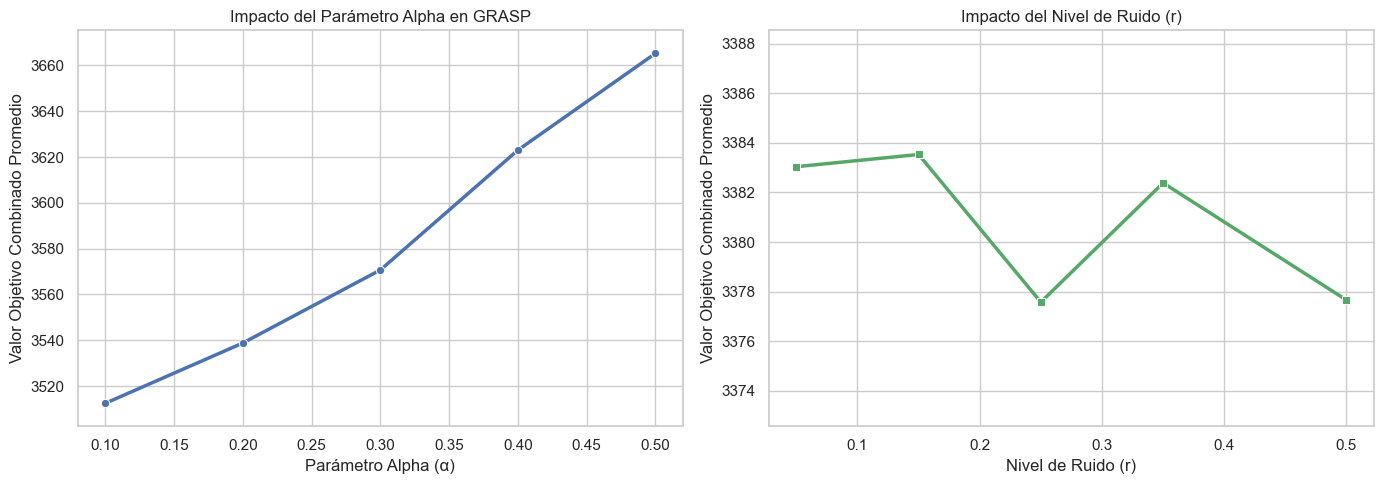

In [10]:
sns.set_theme(style="whitegrid")

df_sens_grasp = df_sensibilidad[df_sensibilidad["Metodo"] == "GRASP"]
df_sens_ruido = df_sensibilidad[df_sensibilidad["Metodo"] == "Ruido"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.lineplot(
    data=df_sens_grasp, x="Valor_Parametro", y="F_Obj", marker="o", ax=axes[0], color="b", linewidth=2.5, errorbar=None
)
axes[0].set_title("Impacto del Parámetro Alpha en GRASP")
axes[0].set_xlabel("Parámetro Alpha (α)")
axes[0].set_ylabel("Valor Objetivo Combinado Promedio")

y_min_g = df_sens_grasp.groupby("Valor_Parametro")["F_Obj"].mean().min()
y_max_g = df_sens_grasp.groupby("Valor_Parametro")["F_Obj"].mean().max()
axes[0].set_ylim(y_min_g - 10, y_max_g + 10)

sns.lineplot(
    data=df_sens_ruido, x="Valor_Parametro", y="F_Obj", marker="s", ax=axes[1], color="g", linewidth=2.5, errorbar=None
)
axes[1].set_title("Impacto del Nivel de Ruido (r)")
axes[1].set_xlabel("Nivel de Ruido (r)")
axes[1].set_ylabel("Valor Objetivo Combinado Promedio")

y_min_r = df_sens_ruido.groupby("Valor_Parametro")["F_Obj"].mean().min()
y_max_r = df_sens_ruido.groupby("Valor_Parametro")["F_Obj"].mean().max()
axes[1].set_ylim(y_min_r - 5, y_max_r + 5)

plt.tight_layout()
plt.show()

### Ejecución algoritmos en las instancias

In [ ]:
res_c, res_g, res_r = {}, {}, {}
resumen = []
    
print(f"Ejecutando algoritmos sobre {len(archivos)} instancias\n")
    
for archivo in archivos:
    inst = leer_instancia(archivo)
    nom = inst["nombre"]
        
    lb_z1 = calcular_cota_inferior_z1(inst)
    lb_f = round(100.0 * lb_z1, 2)
        
    sol_c, z1_c, z2_c, obj_c, t_c = algoritmo_constructivo(inst)
    res_c[nom] = (sol_c, z1_c, z2_c, obj_c, t_c)
    gap_c = ((obj_c - lb_f) / lb_f) * 100.0 if lb_f > 0 else 0
        
    sol_g, z1_g, z2_g, obj_g, t_g = algoritmo_grasp(inst)
    res_g[nom] = (sol_g, z1_g, z2_g, obj_g, t_g)
    gap_g = ((obj_g - lb_f) / lb_f) * 100.0 if lb_f > 0 else 0
        
    sol_r, z1_r, z2_r, obj_r, t_r = algoritmo_ruido(inst)
    res_r[nom] = (sol_r, z1_r, z2_r, obj_r, t_r)
    gap_r = ((obj_r - lb_f) / lb_f) * 100.0 if lb_f > 0 else 0
        
    resumen.append({
        "Instancia": nom,
        "LB_Z1": lb_z1,
        "LB_F": round(lb_f, 2),
        "Obj (Const)": round(obj_c, 2), "GAP% Const": round(gap_c, 2), "Segs Const": round(t_c, 3),
        "Obj (GRASP)": round(obj_g, 2), "GAP% GRASP": round(gap_g, 2), "Segs GRASP": round(t_g, 3),
        "Obj (Ruido)": round(obj_r, 2), "GAP% Ruido": round(gap_r, 2), "Segs Ruido": round(t_r, 3),
    })
        
guardar_resultados_excel(res_c, "constructivo")
guardar_resultados_excel(res_g, "GRASP")
guardar_resultados_excel(res_r, "Ruido")
    
df_resultados = pd.DataFrame(resumen)
display(df_resultados)

Ejecutando algoritmos sobre 19 instancias



In [ ]:
ganadores = []
for index, row in df_resultados.iterrows():
    f_const = row['Obj (Const)']  
    f_grasp = row['Obj (GRASP)']  
    f_ruido = row['Obj (Ruido)']  
    
    min_f = min(f_const, f_grasp, f_ruido)
    
    ganador = []
    if f_const == min_f: ganador.append("Constructivo")
    if f_grasp == min_f: ganador.append("GRASP")
    if f_ruido == min_f: ganador.append("Ruido")
    
    ganadores.append({
        "Instancia": row["Instancia"],
        "Mejor_Metodo": ", ".join(ganador),
        "Min_F": min_f
    })

df_ganadores = pd.DataFrame(ganadores)
print("Conteo de victorias por método:")
display(df_ganadores["Mejor_Metodo"].value_counts())

display(df_ganadores)

resumen_global = pd.DataFrame({
    "Método": ["Constructivo", "GRASP", "Ruido"],
    "Promedio_Funcion_Objetivo (F)": [
        df_resultados['Obj (Const)'].mean(),
        df_resultados['Obj (GRASP)'].mean(),
        df_resultados['Obj (Ruido)'].mean()
    ],
    "Promedio_GAP (%)": [
        df_resultados['GAP% Const'].mean(),
        df_resultados['GAP% GRASP'].mean(),
        df_resultados['GAP% Ruido'].mean()
    ],
    "Tiempo_Promedio (s)": [
        df_resultados['Segs Const'].mean(),
        df_resultados['Segs GRASP'].mean(),
        df_resultados['Segs Ruido'].mean()
    ]
})

resumen_global = resumen_global.round(4)
print("Tabla Comparativa")
display(resumen_global)

In [ ]:
# Promedio del GAP para cada método

gap_promedio = pd.DataFrame({
    "Método": [
        "Constructivo",
        "GRASP",
        "Ruido"
    ],
    "GAP": [
        df_resultados["GAP% Const"].mean(),
        df_resultados["GAP% GRASP"].mean(),
        df_resultados["GAP% Ruido"].mean()
    ]
})

plt.figure(figsize=(8, 5))

plt.bar(
    gap_promedio["Método"],
    gap_promedio["GAP"]
)

plt.xlabel("Método")
plt.ylabel("GAP promedio (%)")
plt.title("Comparación de calidad mediante GAP promedio")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
df_gap_instancias = pd.DataFrame({
    "Instancia": df_resultados["Instancia"],
    "Constructivo": df_resultados["GAP% Const"],
    "GRASP": df_resultados["GAP% GRASP"],
    "Ruido": df_resultados["GAP% Ruido"]
})

df_gap_instancias
plt.figure(figsize=(12, 6))

plt.plot(
    df_gap_instancias["Instancia"],
    df_gap_instancias["Constructivo"],
    marker="o",
    label="Constructivo"
)

plt.plot(
    df_gap_instancias["Instancia"],
    df_gap_instancias["GRASP"],
    marker="o",
    label="GRASP"
)

plt.plot(
    df_gap_instancias["Instancia"],
    df_gap_instancias["Ruido"],
    marker="o",
    label="Ruido"
)

plt.xlabel("Instancia")
plt.ylabel("GAP (%)")
plt.title("GAP obtenido por método en cada instancia")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Comparación tiempos de computo

In [ ]:
tiempos_por_solucion = pd.DataFrame({
    "Método": ["Constructivo", "GRASP", "Ruido"],
    "Tiempo_Por_Solucion (s)": [
        df_resultados['Segs Const'].mean() / 1,        
        df_resultados['Segs GRASP'].mean() / nsol,   
        df_resultados['Segs Ruido'].mean() / nsol    
    ]
})

print("Comparación")
display(tiempos_por_solucion.round(6))

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=tiempos_por_solucion,
    x="Método",
    y="Tiempo_Por_Solucion (s)",
    hue="Método",
    palette="viridis",
    legend=False
)
plt.title("Tiempo Promedio de Cómputo por Solución Generada", fontsize=14, pad=15)
plt.xlabel("Algoritmo", fontsize=12)
plt.ylabel("Tiempo (segundos)", fontsize=12)
ax.bar_label(ax.containers[0], fmt='%.6f', padding=3, fontsize=10)
plt.yscale('log')
plt.tight_layout()
plt.show()

### Validación de resultados

In [ ]:
infactibles_const = (df_resultados['Obj (Const)'] == 999999.0).sum()
infactibles_grasp = (df_resultados['Obj (GRASP)'] == 999999.0).sum()
infactibles_ruido = (df_resultados['Obj (Ruido)'] == 999999.0).sum()
print(f"Soluciones infactibles en Constructivo: {infactibles_const}")
print(f"Soluciones infactibles en GRASP: {infactibles_grasp}")
print(f"Soluciones infactibles en Ruido: {infactibles_ruido}")

if (infactibles_const + infactibles_grasp + infactibles_ruido) == 0:
    print("\nCero soluciones infactibles encontradas. Todas pasaron la validación de factibilidad.")
resumen_gap = pd.DataFrame({
    "Método": ["Constructivo", "GRASP", "Ruido"],
    "Gap Promedio (%)": [
        df_resultados['GAP% Const'].mean(),
        df_resultados['GAP% GRASP'].mean(),
        df_resultados['GAP% Ruido'].mean()
    ],
    "Gap Mínimo (%)": [
        df_resultados['GAP% Const'].min(),
        df_resultados['GAP% GRASP'].min(),
        df_resultados['GAP% Ruido'].min()
    ],
    "Gap Máximo (%)": [
        df_resultados['GAP% Const'].max(),
        df_resultados['GAP% GRASP'].max(),
        df_resultados['GAP% Ruido'].max()
    ]
})

print("Tabla de Validación de Calidad:")
display(resumen_gap.round(4))

resumen_tiempo_val = pd.DataFrame({
    "Método": ["Constructivo", "GRASP", "Ruido"],
    "Tiempo Promedio Corrida (s)": [
        df_resultados['Segs Const'].mean(),
        df_resultados['Segs GRASP'].mean(),
        df_resultados['Segs Ruido'].mean()
    ],
    "Tiempo Promedio por Solución (s)": [
        df_resultados['Segs Const'].mean() / 1,
        df_resultados['Segs GRASP'].mean() / nsol,
        df_resultados['Segs Ruido'].mean() / nsol
    ]
})

print("\nTabla de Validación de Eficiencia Computacional:")
display(resumen_tiempo_val.round(4))